Transformer Prerequisites
====

Before building the full Transformer encoder-decoder architecture, we first need a few reusable input-processing components.

- The original Transformer used a subword tokenizer based on Byte Pair Encoding (BPE).
- It used a shared source-target vocabulary with about 37,000 tokens for the English-German translation setup.
- This is different from GPT-2's byte-level BPE tokenizer, which has no dedicated padding token.
- For this educational implementation, we will train a small classic BPE tokenizer with explicit special tokens:
  - `[PAD]` for padding batches to the same length
  - `[BOS]` for the beginning of a sequence
  - `[EOS]` for the end of a sequence
  - `[UNK]` for unknown tokens
- We will build padding masks from sequence lengths, instead of assuming a token ID always means padding.
- We will implement sinusoidal positional embeddings, matching the original Transformer instead of learned positional embeddings.
- Finally, we will combine token embeddings and positional embeddings to produce the input tensor used by the encoder and decoder blocks.


### 1. Classic BPE tokenizer

The original Transformer used BPE subword tokenization with a shared source-target vocabulary for translation. In this notebook, we use Hugging Face `tokenizers` to train a small shared BPE tokenizer on bilingual English-German text.

For a real English-German model, train this tokenizer on the combined source and target text from the training corpus. The tiny examples below are only for illustrating the mechanics.

In [1]:
from pathlib import Path

from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.processors import TemplateProcessing
from tokenizers.trainers import BpeTrainer

In [2]:
def find_repo_root(start: Path = Path.cwd()) -> Path:
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("Could not find repo root containing pyproject.toml")


repo_root = find_repo_root()
tokenizer_dir = repo_root / "data" / "tokenizers"
tokenizer_dir.mkdir(parents=True, exist_ok=True)

tokenizer_path = tokenizer_dir / "classic_bpe_en_de.json"
print(f"Tokenizer path: {tokenizer_path}")

Tokenizer path: /home/pyml/git_kmehr/llm-recipes/data/tokenizers/classic_bpe_en_de.json


In [3]:
english_german_examples = [
    "Hello, how are you?",
    "Hallo, wie geht es dir?",
    "The Transformer architecture uses attention mechanisms.",
    "Die Transformer-Architektur verwendet Attention-Mechanismen.",
    "The encoder reads the source sentence.",
    "Der Encoder liest den Quellsatz.",
    "The decoder generates the target sentence.",
    "Der Decoder erzeugt den Zielsatz.",
    "Machine translation maps text from one language to another.",
    "Maschinelle Übersetzung bildet Text von einer Sprache in eine andere ab.",
]

# Original-Transformer scale was about 37,000 tokens.
# This tiny demo corpus is too small for that, so we use a smaller vocabulary.
vocab_size = 1_000
special_tokens = ["[PAD]", "[BOS]", "[EOS]", "[UNK]"]

tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
tokenizer.pre_tokenizer = Whitespace()

trainer = BpeTrainer(
    vocab_size=vocab_size,
    special_tokens=special_tokens,
    show_progress=False,
)

tokenizer.train_from_iterator(english_german_examples, trainer=trainer)

tokenizer.post_processor = TemplateProcessing(
    single="[BOS] $A [EOS]",
    pair="[BOS] $A [EOS] $B:1 [EOS]:1",
    special_tokens=[
        ("[BOS]", tokenizer.token_to_id("[BOS]")),
        ("[EOS]", tokenizer.token_to_id("[EOS]")),
    ],
)

tokenizer.save(str(tokenizer_path))

print(f"Trained vocabulary size: {tokenizer.get_vocab_size()}")
for token in special_tokens:
    print(f"{token}: {tokenizer.token_to_id(token)}")

Trained vocabulary size: 221
[PAD]: 0
[BOS]: 1
[EOS]: 2
[UNK]: 3


In [4]:
# Load the tokenizer from disk, like we would in later notebooks.
tokenizer = Tokenizer.from_file(str(tokenizer_path))

text_en = "The encoder uses attention."
text_de = "Der Encoder verwendet Attention."

encoded_en = tokenizer.encode(text_en)
encoded_de = tokenizer.encode(text_de)

print("English tokens:", encoded_en.tokens)
print("English ids:", encoded_en.ids)
print("German tokens:", encoded_de.tokens)
print("German ids:", encoded_de.ids)

English tokens: ['[BOS]', 'The', 'encoder', 'uses', 'attention', '.', '[EOS]']
English ids: [1, 57, 165, 154, 168, 6, 2]
German tokens: ['[BOS]', 'Der', 'Encoder', 'verwendet', 'Attention', '.', '[EOS]']
German ids: [1, 66, 184, 220, 183, 6, 2]


This tokenizer works for bilingual English-German text because BPE learns subword pieces from whatever training text it sees. If we train one shared tokenizer on both English source sentences and German target sentences, both languages use the same vocabulary and embedding table.

For real experiments, replace the small `english_german_examples` list with lines from a proper parallel corpus, such as WMT English-German data, and increase `vocab_size` toward the original scale.

### 2. Train a reusable tokenizer on Tatoeba English-German data

The tiny sentence list above is useful for understanding the BPE training API, but it is too small to use as the tokenizer for the encoder-decoder notebook. Here we download a larger English-German parallel corpus from the OPUS-hosted Tatoeba data and save a shared BPE tokenizer that later notebooks can load from disk.

Tatoeba text data is released under Creative Commons licenses. If you use the data outside these notebooks, make sure to preserve the required attribution.


In [5]:
from urllib.request import urlretrieve
from zipfile import ZipFile

tatoeba_url = "https://object.pouta.csc.fi/OPUS-Tatoeba/v2023-04-12/moses/de-en.txt.zip"

data_dir = repo_root / "data" / "raw" / "tatoeba_en_de"
data_dir.mkdir(parents=True, exist_ok=True)

zip_path = data_dir / "de-en.txt.zip"
english_path = data_dir / "Tatoeba.de-en.en"
german_path = data_dir / "Tatoeba.de-en.de"

if not zip_path.exists():
    urlretrieve(tatoeba_url, zip_path)

if not english_path.exists() or not german_path.exists():
    with ZipFile(zip_path) as zip_file:
        zip_file.extractall(data_dir)

max_sentence_pairs = 100_000

english_sentences = english_path.read_text(encoding="utf-8").splitlines()
german_sentences = german_path.read_text(encoding="utf-8").splitlines()

sentence_pairs = list(zip(english_sentences, german_sentences))[:max_sentence_pairs]
tokenizer_training_texts = [text for pair in sentence_pairs for text in pair]

print(f"Downloaded corpus to: {data_dir}")
print(f"English sentences: {len(english_sentences):,}")
print(f"German sentences: {len(german_sentences):,}")
print(f"Sentence pairs used for tokenizer training: {len(sentence_pairs):,}")
print("Example pair:")
print("EN:", sentence_pairs[0][0])
print("DE:", sentence_pairs[0][1])


Downloaded corpus to: /home/pyml/git_kmehr/llm-recipes/data/raw/tatoeba_en_de
English sentences: 322,413
German sentences: 322,413
Sentence pairs used for tokenizer training: 100,000
Example pair:
EN: Let's try something. 
DE: Lass uns etwas versuchen! 


In [6]:
tatoeba_tokenizer_path = tokenizer_dir / "tatoeba_bpe_en_de.json"

vocab_size = 16_000
special_tokens = ["[PAD]", "[BOS]", "[EOS]", "[UNK]"]

tatoeba_tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
tatoeba_tokenizer.pre_tokenizer = Whitespace()

trainer = BpeTrainer(
    vocab_size=vocab_size,
    special_tokens=special_tokens,
    show_progress=True,
)

tatoeba_tokenizer.train_from_iterator(tokenizer_training_texts, trainer=trainer)

tatoeba_tokenizer.post_processor = TemplateProcessing(
    single="[BOS] $A [EOS]",
    pair="[BOS] $A [EOS] $B:1 [EOS]:1",
    special_tokens=[
        ("[BOS]", tatoeba_tokenizer.token_to_id("[BOS]")),
        ("[EOS]", tatoeba_tokenizer.token_to_id("[EOS]")),
    ],
)

tatoeba_tokenizer.save(str(tatoeba_tokenizer_path))

print(f"Saved tokenizer to: {tatoeba_tokenizer_path}")
print(f"Vocabulary size: {tatoeba_tokenizer.get_vocab_size():,}")
for token in special_tokens:
    print(f"{token}: {tatoeba_tokenizer.token_to_id(token)}")





Saved tokenizer to: /home/pyml/git_kmehr/llm-recipes/data/tokenizers/tatoeba_bpe_en_de.json
Vocabulary size: 16,000
[PAD]: 0
[BOS]: 1
[EOS]: 2
[UNK]: 3


### 3. Sinusoidal positional embeddings


In [7]:
import torch
import torch.nn as nn

In [8]:
class SinusoidalPositionEmbedding(nn.Module):
    def __init__(self, context_length: int, embedding_dim: int):
        super().__init__()
        self.context_length = context_length
        self.embedding_dim = embedding_dim

        position = torch.arange(context_length).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, embedding_dim, 2) * (-torch.log(torch.tensor(10000.0)) / embedding_dim)
        )

        pe = torch.zeros(context_length, embedding_dim)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe)

    def forward(self, positions: torch.Tensor) -> torch.Tensor:
        assert positions.max() < self.context_length, "position exceeds context_length"
        return self.pe[positions]

In [9]:
embedding_dim = 512
context_length = 512
num_heads = 8

position_embeddings = SinusoidalPositionEmbedding(
    context_length=context_length,
    embedding_dim=embedding_dim,
)

seq_len = len(encoded_en.ids)
positions = torch.arange(seq_len)
pos_emb = position_embeddings(positions)

print(f"positions: {positions}")
print(f"pos_emb.shape: {pos_emb.shape}")
print(f"position 0, first 8 dims: {pos_emb[0, :8]}")

positions: tensor([0, 1, 2, 3, 4, 5, 6])
pos_emb.shape: torch.Size([7, 512])
position 0, first 8 dims: tensor([0., 1., 0., 1., 0., 1., 0., 1.])


In [10]:
# At position 0, sin dimensions are 0 and cos dimensions are 1.
assert torch.allclose(pos_emb[0, 0::2], torch.zeros(embedding_dim // 2))
assert torch.allclose(pos_emb[0, 1::2], torch.ones(embedding_dim // 2))

print("Sinusoidal position embedding sanity check passed.")

Sinusoidal position embedding sanity check passed.


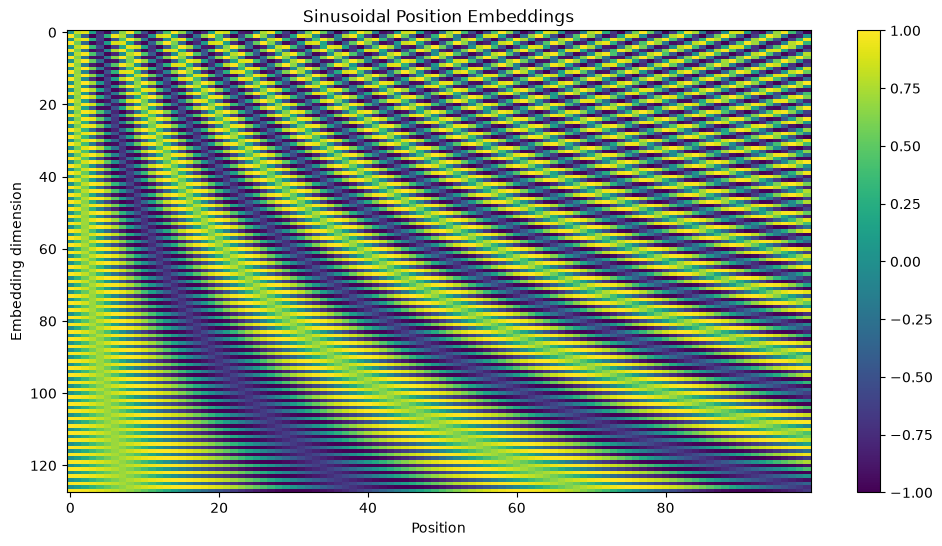

In [11]:
import matplotlib.pyplot as plt

num_positions = 100
num_dims = 128

pe_to_plot = position_embeddings.pe[:num_positions, :num_dims].T

plt.figure(figsize=(12, 6))
plt.imshow(
    pe_to_plot.detach().cpu().numpy(),
    cmap="viridis",
    aspect="auto",
    interpolation="nearest",
)
plt.xlabel("Position")
plt.ylabel("Embedding dimension")
plt.title("Sinusoidal Position Embeddings")
plt.colorbar()
plt.show()

### 4. Different forms of Multihead Attention

 - Multihead Self-Attention (non-causal)
 - Multihead Causal Self-Attention
 - Multihead Cross-Attention

```python
class MultiHeadSelfAttention(nn.Module):
    """Bidirectional self-attention used by the encoder."""

class MultiHeadCausalAttention(nn.Module):
    """Masked self-attention used by the decoder."""

class MultiHeadCrossAttention(nn.Module):
    """Decoder-to-encoder cross-attention."""
```

In [12]:
class MultiHeadSelfAttention(nn.Module):
    """Bidirectional self-attention used by the encoder."""
    def __init__(
            self,
            embedding_dim: int,
            num_heads: int,
            dropout_rate: float = 0.1,
    ):
        super().__init__()
        assert embedding_dim % num_heads == 0, "embedding_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.embedding_dim = embedding_dim
        self.head_dim = embedding_dim // num_heads

        # self.w_attn = nn.Linear(embedding_dim, 3 * embedding_dim)  # for q, k & v
        self.w_q = nn.Linear(embedding_dim, embedding_dim)
        self.w_k = nn.Linear(embedding_dim, embedding_dim)
        self.w_v = nn.Linear(embedding_dim, embedding_dim)
        self.w_o = nn.Linear(embedding_dim, embedding_dim)

        self.attn_dropout = nn.Dropout(dropout_rate)
        self.resid_dropout = nn.Dropout(dropout_rate)

    def forward(self, x: torch.Tensor, attention_mask: torch.Tensor = None) -> torch.Tensor:
        batch_size, seq_len, _ = x.size()

        # Linear projections
        # q, k, v = self.w_attn(x).split(self.embedding_dim, dim=-1)
        q = self.w_q(x)
        k = self.w_k(x)
        v = self.w_v(x)
        # current shapes: [batch_size, seq_len, embedding_dim]

        # split the embedding dimension into multiple heads
        # -> shape: [batch_size, num_heads, seq_len, head_dim]
        q = q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        attn_scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)

        # attention mask (for padding tokens)
        if attention_mask is not None:
            assert attention_mask.shape == (batch_size, seq_len)
            assert attention_mask.dtype == torch.bool
            # attention_mask shape: [batch_size, seq_len]
            attn_scores = attn_scores.masked_fill(
                attention_mask.unsqueeze(1).unsqueeze(2),
                float("-inf"),
            )

        attn_weights = torch.softmax(attn_scores, dim=-1)
        attn_weights = self.attn_dropout(attn_weights)
        output = torch.matmul(attn_weights, v)

        # Concatenate heads and project
        output = output.transpose(1, 2).contiguous().view(batch_size, seq_len, -1)
        output = self.w_o(output)
        output = self.resid_dropout(output)

        return output
    
# testing
x = torch.randn(2, 10, embedding_dim)  # batch_size=2, seq_len=10
mha = MultiHeadSelfAttention(embedding_dim=embedding_dim, num_heads=num_heads)
output = mha(x)
print(f"Input shape: {x.shape}")
print(f"Output shape: {output.shape}")

Input shape: torch.Size([2, 10, 512])
Output shape: torch.Size([2, 10, 512])


In [13]:
class MultiHeadCausalAttention(nn.Module):
    """Masked self-attention used by the decoder."""
    def __init__(
            self,
            embedding_dim: int,
            num_heads: int,
            context_length,
            dropout_rate: float = 0.1,
    ):
        super().__init__()
        assert embedding_dim % num_heads == 0, "embedding_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.embedding_dim = embedding_dim
        self.head_dim = embedding_dim // num_heads

        self.w_q = nn.Linear(embedding_dim, embedding_dim)
        self.w_k = nn.Linear(embedding_dim, embedding_dim)
        self.w_v = nn.Linear(embedding_dim, embedding_dim)
        self.w_o = nn.Linear(embedding_dim, embedding_dim)

        self.attn_dropout = nn.Dropout(dropout_rate)
        self.resid_dropout = nn.Dropout(dropout_rate)

        # Precompute the causal mask
        causal_mask = torch.triu(
            torch.ones(context_length, context_length, dtype=torch.bool),
            diagonal=1,
        )
        self.register_buffer("causal_mask", causal_mask)


    def forward(self, x: torch.Tensor, attention_mask: torch.Tensor = None) -> torch.Tensor:
        batch_size, seq_len, _ = x.size()

        q = self.w_q(x)
        k = self.w_k(x)
        v = self.w_v(x)
        # current shapes: [batch_size, seq_len, embedding_dim]

        # split the embedding dimension into multiple heads
        # -> shape: [batch_size, num_heads, seq_len, head_dim]
        q = q.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        attn_scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)

        # Causal mask
        assert seq_len <= self.causal_mask.size(0), "sequence length exceeds context_length"
        causal_mask = self.causal_mask[:seq_len, :seq_len]
        attn_scores = attn_scores.masked_fill(
            causal_mask.unsqueeze(0).unsqueeze(0),
            float('-inf')
        )

        # attention mask (for padding tokens)
        if attention_mask is not None:
            assert attention_mask.shape == (batch_size, seq_len)
            assert attention_mask.dtype == torch.bool
            # attention_mask shape: [batch_size, seq_len]
            attn_scores = attn_scores.masked_fill(
                attention_mask.unsqueeze(1).unsqueeze(2),
                float("-inf"),
            )

        attn_weights = torch.softmax(attn_scores, dim=-1)
        attn_weights = self.attn_dropout(attn_weights)
        output = torch.matmul(attn_weights, v)

        # Concatenate heads and project
        output = output.transpose(1, 2).contiguous().view(batch_size, seq_len, -1)
        output = self.w_o(output)
        output = self.resid_dropout(output)

        return output

# testing
x = torch.randn(2, 10, embedding_dim)  # batch_size=2
mha_causal = MultiHeadCausalAttention(embedding_dim, num_heads, context_length=512)
output = mha_causal(x)
print(f"Input shape: {x.shape}")
print(f"Output shape: {output.shape}")

Input shape: torch.Size([2, 10, 512])
Output shape: torch.Size([2, 10, 512])


In [14]:
class MultiHeadCrossAttention(nn.Module):
    """Decoder-to-encoder cross-attention."""
    def __init__(
            self,
            embedding_dim,
            num_heads,
            context_length,
            dropout=0.1
        ):
        super().__init__()
        assert embedding_dim % num_heads == 0, "embedding_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.embedding_dim = embedding_dim
        self.head_dim = embedding_dim // num_heads

        self.w_q = nn.Linear(embedding_dim, embedding_dim)
        self.w_k = nn.Linear(embedding_dim, embedding_dim)
        self.w_v = nn.Linear(embedding_dim, embedding_dim)
        self.w_o = nn.Linear(embedding_dim, embedding_dim)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        causal_mask = torch.triu(
            torch.ones(context_length, context_length, dtype=torch.bool),
            diagonal=1,
        )
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x, kv_states, attention_mask=None):
        batch_size, target_len, _ = x.size()
        src_len = kv_states.size(1)
        assert target_len <= self.causal_mask.size(0), "sequence length exceeds context_length"
        assert src_len <= self.causal_mask.size(0), "source length exceeds context_length"

        q = self.w_q(x)
        k = self.w_k(kv_states)
        v = self.w_v(kv_states)
        # current shapes: [batch_size, seq_len, embedding_dim]

        # split the embedding dimension into multiple heads
        # -> shape: [batch_size, num_heads, seq_len, head_dim]
        q = q.view(batch_size, target_len, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, src_len, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, src_len, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        attn_scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        
        # Causal mask
        causal_mask = self.causal_mask[:target_len, :src_len]
        attn_scores = attn_scores.masked_fill(
            causal_mask.unsqueeze(0).unsqueeze(0),
            float('-inf')
        )

        # attention mask (for padding tokens)
        if attention_mask is not None:
            assert attention_mask.shape == (batch_size, src_len)
            assert attention_mask.dtype == torch.bool
            # attention_mask shape: [batch_size, src_len]
            attn_scores = attn_scores.masked_fill(
                attention_mask.unsqueeze(1).unsqueeze(2),
                float("-inf"),
            )

        attn_weights = torch.softmax(attn_scores, dim=-1)
        attn_weights = self.attn_dropout(attn_weights)
        output = torch.matmul(attn_weights, v)

        # Concatenate heads and project
        output = output.transpose(1, 2).contiguous().view(batch_size, target_len, -1)
        output = self.w_o(output)
        output = self.resid_dropout(output)

        return output
    
# testing
x = torch.randn(2, 10, embedding_dim)  # batch_size=2
kv_states = torch.randn(2, 15, embedding_dim)  # source length=15
mha_cross = MultiHeadCrossAttention(embedding_dim, num_heads, context_length=512)
output = mha_cross(x, kv_states)
print(f"Input shape: {x.shape}")
print(f"KV states shape: {kv_states.shape}")
print(f"Output shape: {output.shape}")

Input shape: torch.Size([2, 10, 512])
KV states shape: torch.Size([2, 15, 512])
Output shape: torch.Size([2, 10, 512])


## Summary and Next Step

In this notebook, we added the practical prerequisites for building a Transformer encoder-decoder model.

First, we trained a small shared English-German BPE tokenizer from a tiny sentence list. This gave us a compact example of how BPE learns subword pieces and how special tokens such as `[PAD]`, `[BOS]`, `[EOS]`, and `[UNK]` become part of the vocabulary.

Then, we added a larger Tatoeba English-German dataset section and trained a reusable shared BPE tokenizer that is saved to disk. This tokenizer is the one we can load in the encoder-decoder notebook instead of retraining from scratch.

Finally, we implemented sinusoidal positional embeddings. Unlike learned positional embeddings, these are fixed functions of token position. They let the model receive information about word order without adding trainable position parameters.

In the next notebook, we will use these pieces to build the core Transformer encoder-decoder architecture. We will prepare source and target token batches, add token and positional embeddings, implement encoder self-attention, decoder causal self-attention, and decoder cross-attention, then combine them into encoder and decoder blocks.
